In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import matplotlib.pyplot as plt

### Objetivo

Implementar un agente de RL que aprenda a invertir en un entorno simulado con un único activo.

### Definición del entorno

El **estado** (observación) es una tupla de la forma ``(tendencia, posición)`` en la que:

- ``tendencia`` es la tendencia del precio, calculada a partir de las últimas 6 observaciones.

- ``posición`` es $1$ si el agente posee el activo y $0$ si no lo posee.

En cada momento, las **acciones** son:

- $0$ = vender

- $1$ = mantener

- $2$ = comprar

Obviamente, la acción *vender* sólo tendrá efecto si el agente es poseedor del activo, y la acción *comprar* sólo tendrá efecto cuando el agente no posee el activo.


In [2]:
class SimpleTradingEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, prices):
        super(SimpleTradingEnv, self).__init__()
        self.prices = prices
        self.max_steps = len(prices) - 1

        # Acciones: 0 = Vender, 1 = Mantener, 2 = Comprar
        self.action_space = spaces.Discrete(3)

        # Estado: [tendencia_precio (-1 a 1), posicion_actual (0 o 1)]
        self.observation_space = spaces.Box(
            low=np.array([-1.0, 0], dtype=np.float32),
            high=np.array([1.0, 1], dtype=np.float32),
            dtype=np.float32
        )

    def reset(self, seed=None):
        super().reset(seed=seed)
        self.current_step = 5  # Empezar con suficiente historia para la media
        self.position = 0      # 0: sin activo, 1: con activo

        # Gestión del capital
        self.initial_balance = 1000.0
        self.balance = self.initial_balance  # Valor total del portafolio (Efectivo + Activos)
        self.cash = self.initial_balance     # Dinero en efectivo disponible
        self.shares = 0.0                    # Cantidad de acciones poseídas

        return self._get_obs(), {}

    def _get_obs(self):
        # Calcular tendencia simple basada en los últimos 5 pasos
        window = self.prices[self.current_step - 5 : self.current_step + 1]
        trend = (window[-1] - np.mean(window)) / np.mean(window)
        return np.array([np.clip(trend, -1.0, 1.0), self.position], dtype=np.float32)

    def step(self, action):
        prev_price = self.prices[self.current_step]
        self.current_step += 1
        curr_price = self.prices[self.current_step]

        reward = 0.0
        cost_rate = 0.001  # Comisión del 0.1% por transacción

        # 1. Ejecutar acciones y actualizar efectivo/acciones
        if action == 2 and self.position == 0:  # Comprar
            # Usar todo el efectivo disponible para comprar acciones al precio anterior
            commission = self.cash * cost_rate
            effective_cash = self.cash - commission
            self.shares = effective_cash / prev_price
            self.cash = 0.0
            self.position = 1
            reward -= cost_rate

        elif action == 0 and self.position == 1:  # Vender
            # Vender todas las acciones al precio anterior
            sale_value = self.shares * prev_price
            commission = sale_value * cost_rate
            self.cash = sale_value - commission
            self.shares = 0.0
            self.position = 0
            reward -= cost_rate

        # 2. Calcular recompensa por variación del precio si mantiene la posición
        if self.position == 1:
            price_change = (curr_price - prev_price) / prev_price
            reward += price_change

        # 3. Actualizar el balance total (Net Worth) al finalizar el paso
        if self.position == 1:
            self.balance = self.cash + (self.shares * curr_price)
        else:
            self.balance = self.cash

        terminated = self.current_step >= self.max_steps
        truncated = False

        # Opcional: puedes pasar el balance actual en el diccionario de info
        info = {"balance": self.balance}

        return self._get_obs(), reward, terminated, truncated, info

### Funciones para generar precios

Se proponen cuatro funciones generadoras de precios. Las pruebas deben hacerse al menos con estas cuatro funciones. Si se desea, pueden añadirse otras funciones de diferentes características, o incluso probar con alguna serie de precios real.

#### 1. Tendencia suave + componente cíclica

In [3]:
def generar_precios(n_steps=1000):
    # Combinar una tendencia suave (drift) + componente cíclico + ruido
    t = np.linspace(0, 50, n_steps)
    drift = 0.0005 * t
    ciclo = np.sin(t) * 0.05
    ruido = np.random.normal(0, 0.1, n_steps)

    # Precio base acumulado
    retornos = drift + ciclo + ruido
    precios = 100 * np.cumprod(1 + retornos)
    return precios

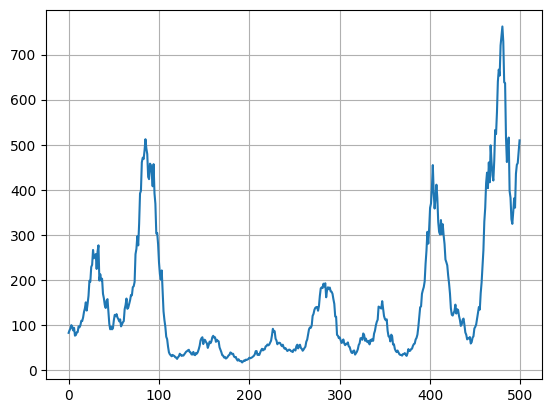

In [4]:
precios = generar_precios(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 2. Movimiento browniano

In [5]:
def generar_precios_browniano(n_steps=1000, start_price=100.0, mu=0.0001, sigma=0.02):
    """
    Genera precios usando Movimiento Browniano Geométrico.
    - mu: Tendencia o deriva esperada (drift).
    - sigma: Volatilidad (desviación estándar de los retornos).
    """
    dt = 1.0
    # Retornos logarítmicos distribuidos normalmente
    retornos = np.random.normal((mu - 0.5 * sigma**2) * dt, sigma * np.sqrt(dt), n_steps)
    precios = start_price * np.cumprod(np.exp(retornos))
    return precios

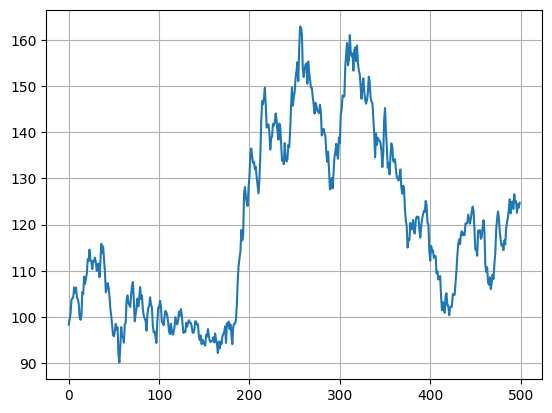

In [6]:
precios = generar_precios_browniano(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 3. Reversión a la media

In [7]:
def generar_precios_reversion_media(n_steps=1000, start_price=100.0, mean_price=100.0, kappa=0.05, volatility=0.02):
    """
    Genera precios que tienden a revertir hacia un valor medio.
    - mean_price: El precio objetivo o de equilibrio.
    - kappa: Velocidad de reversión (cuánto más alto, más rápido vuelve al valor medio).
    - volatility: Magnitud del ruido aleatorio añadido en cada paso.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    for t in range(1, n_steps):
        # Fuerza de atracción hacia la media + ruido aleatorio
        delta = kappa * (mean_price - precios[t-1]) + np.random.normal(0, volatility * mean_price)
        precios[t] = precios[t-1] + delta

        # Evitar precios negativos o cero por seguridad
        precios[t] = max(precios[t], 0.1)

    return precios

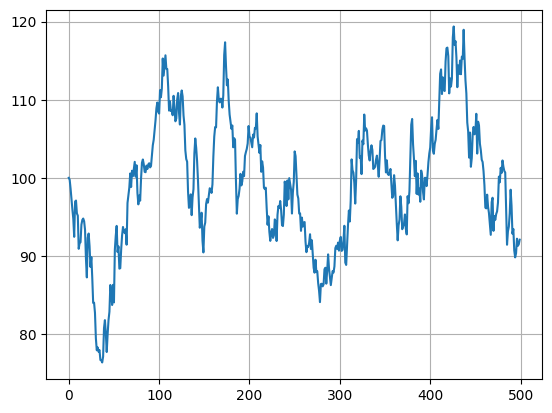

In [8]:
precios = generar_precios_reversion_media(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

#### 4. Alternancia entre regímenes alcistas y bajistas

In [9]:
def generar_precios_regimenes(n_steps=1000, start_price=100.0):
    """
    Genera precios alternando entre regímenes alcistas y bajistas de forma estocástica.
    """
    precios = np.zeros(n_steps)
    precios[0] = start_price

    # Estado inicial: 0 = Alcista, 1 = Bajista
    estado = 0

    retornos = []
    for _ in range(n_steps):
        # Probabilidad de cambiar de régimen en cada paso
        if np.random.rand() < 0.02:
            estado = 1 - estado

        if estado == 0:  # Régimen alcista
            ret = np.random.normal(0.001, 0.01)
        else:            # Régimen bajista (caídas con más ruido)
            ret = np.random.normal(-0.0015, 0.025)

        retornos.append(ret)

    retornos = np.array(retornos)
    precios = start_price * np.cumprod(1 + retornos)

    # Asegurar que no haya valores negativos
    precios = np.maximum(precios, 0.1)
    return precios

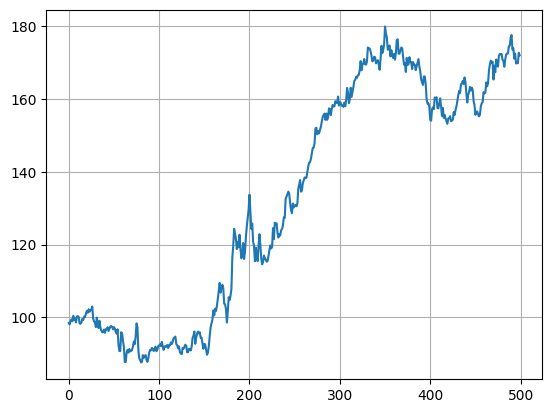

In [10]:
precios = generar_precios_regimenes(n_steps=500)

plt.figure()
plt.plot(precios)
plt.grid()
plt.show()

### Agente aleatorio

Como línea base, se proporciona un agente aleatorio que en cada instante selecciona la acción al azar. A continuación se compara su rendimiento en un episodio con la estrategia *buy & hold*.

In [11]:
n_steps = 500
prices = generar_precios(n_steps)
env = SimpleTradingEnv(prices)

obs, info = env.reset()
terminated = False
step_count = 0

balances = [env.balance]
actions_taken = []
positions = []

while not terminated:
    action = env.action_space.sample()
    positions.append(env.position)
    actions_taken.append(action)

    obs, reward, terminated, truncated, info = env.step(action)
    balances.append(env.balance)

positions = np.array(positions)
actions_taken = np.array(actions_taken)
valid_prices = prices[5:-1]

In [12]:
prices_on = valid_prices.copy()
prices_on[positions==0] = np.nan
prices_off = valid_prices.copy()
prices_off[positions==1] = np.nan

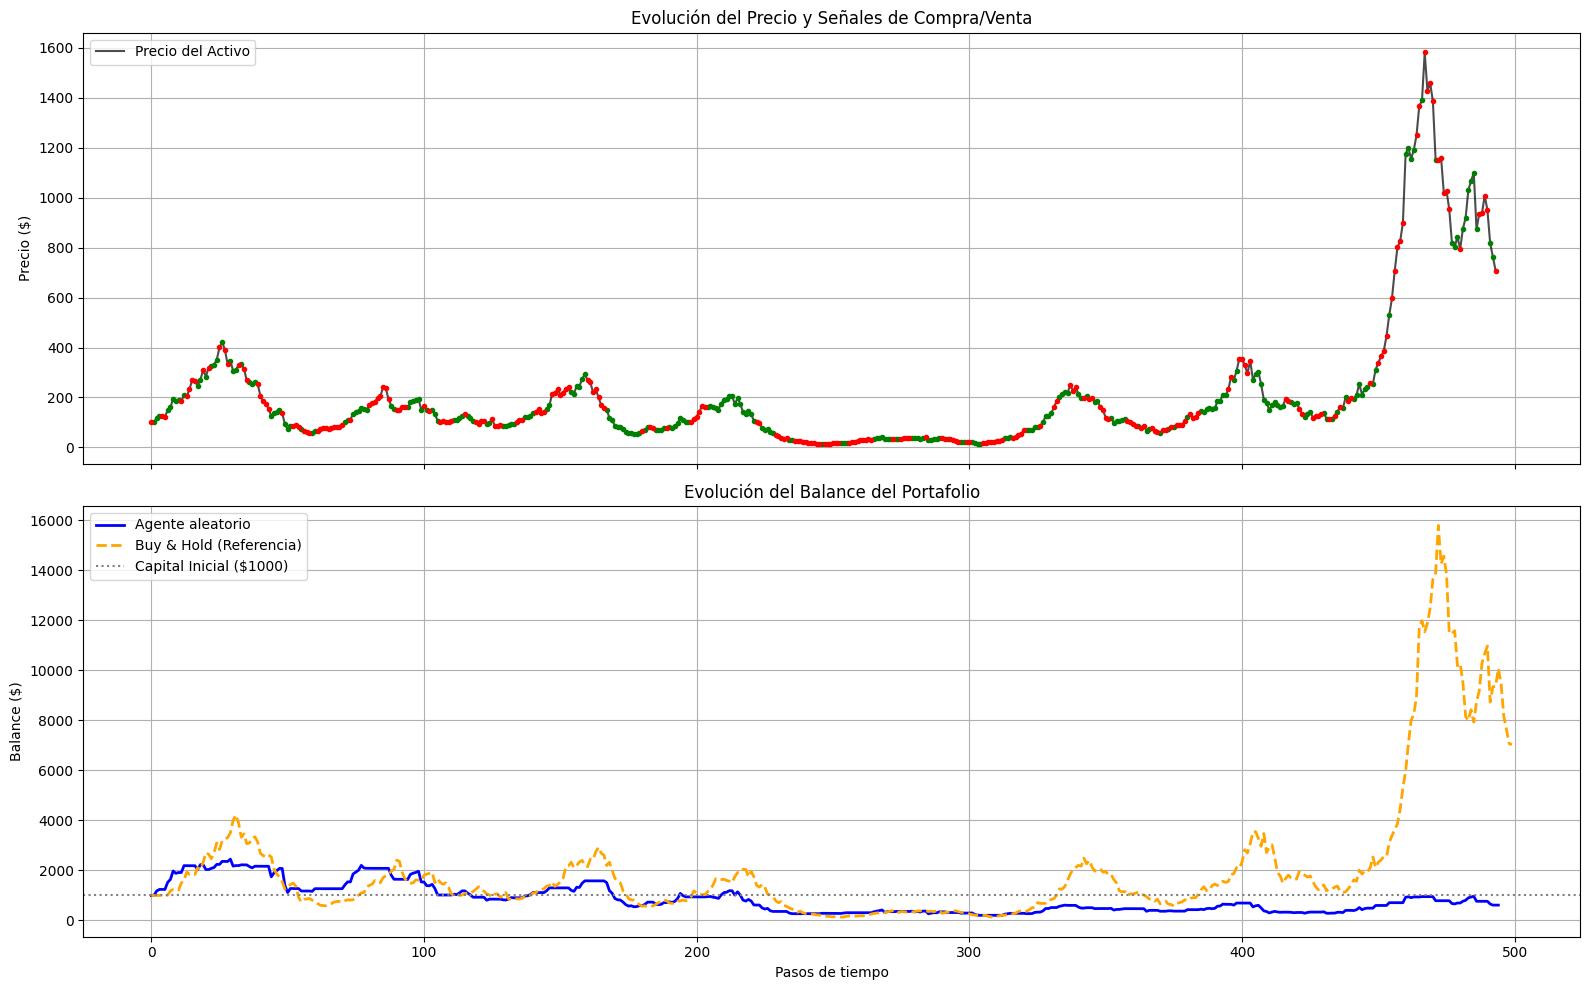

In [13]:
# --- Estrategia Buy & Hold para el panel de balance ---
bh_initial_cash = 1000.0
bh_start_price = prices[5]
bh_shares = (bh_initial_cash * 0.999) / bh_start_price
bh_balances = [bh_initial_cash if i < 5 else bh_shares * p for i, p in enumerate(prices)]

# --- Crear la figura con 2 Subgráficas ---
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

# PANEL 1: Evolución del precio y señales de Trading
ax1.plot(valid_prices, label="Precio del Activo", color="black", alpha=0.7, linewidth=1.5)
ax1.plot(prices_on, 'g.')
ax1.plot(prices_off, 'r.')
ax1.set_title("Evolución del Precio y Señales de Compra/Venta")
ax1.set_ylabel("Precio ($)")
ax1.legend(loc="upper left")
ax1.grid(True)

# PANEL 2: Evolución del Balance (Portafolio)
ax2.plot(balances, label="Agente aleatorio", color="blue", linewidth=2)
ax2.plot(bh_balances, label="Buy & Hold (Referencia)", color="orange", linestyle="--", linewidth=2)
ax2.axhline(y=1000, color="gray", linestyle=":", label="Capital Inicial ($1000)")

ax2.set_title("Evolución del Balance del Portafolio")
ax2.set_xlabel("Pasos de tiempo")
ax2.set_ylabel("Balance ($)")
ax2.legend(loc="upper left")
ax2.grid(True)

plt.tight_layout()
plt.show()

### Ejercicios y notas sobre la implementación

1. Implementar los algoritmos vistos en clase y probarlos con distintas funciones de generación de los precios. Deben implementarse al menos los algoritmos *DQN* y *A3C*, usando al menos las cuatro funciones de generación de precio propuestas.

   - Cada agente debe entrenarse con varios (muchos) episodios, y cada episodio debería usar una serie de precios distinta, aunque todas deberían ser generadas por la misma función. De este modo el agente puede aprender las regularidades de cada tipo de *mercado* sin repetir siempre los mismos datos para entrenar.

   - Para evaluar los agentes entrenados, se deberían usar datos de *test*, series de precios nuevas generadas a partir de la misma función usada durante el entrenamiento. Los resultados deberían promediarse sobre varias series de test.

2. Analizar las soluciones obtenidas para cada función de generación de precios, y compararlas con el agente aleatorio y con la estrategia *buy & hold*. Razonar si la estrategia encontrada en cada caso es la esperada.

3. Ajustar de manera adecuada los hiperparámetros de cada modelo, en particular el factor de aprendizaje $\alpha$, la tasa de exploración $\epsilon$ (probablemente con decaimiento temporal), el factor de descuento $\gamma$, y el número de episodios de entrenamiento.

4. Comparar en una tabla las soluciones obtenidas con cada algoritmo, incluyendo los *baselines*, sobre cada problema (función generadora de precios). Analizar al menos el rendimiento y el tiempo de convergencia.



### Entrega

Debe entregarse un documento en pdf de un **máximo de dos páginas** con un resumen de las pruebas realizadas, los resultados obtenidos y las conclusiones extraidas.

Las entregas se harán por grupos. Cada grupo de TFM realizará una entrega.

La fecha tope para la entrega es el **5/11/2026**, a las **23:59**.

**Importante:** Una primera versión del documento se deberá entregar por e-mail a manuel.smontanes@gmail.com antes de la clase del jueves 5 de noviembre. En dicha clase cada grupo presentará su trabajo y lo discutirá con el profesor durante un máximo de 15 minutos. Los comentarios recibidos pueden usarse para mejorar el documento para la entrega final.

De cara a organizar las presentaciones, un representante de cada grupo debe enviar un e-mail al profesor antes del martes 3 de noviembre. Ese mismo día os indicaré, mediante mensaje a los representantes, el orden de presentación.

### Evaluación

La realización de los ejercicios y pruebas propuestos garantiza el aprobado en la práctica (50%). El otro 50% se obtendrá valorando la realización de pruebas que vayan más allá de los mínimos planteados (10%), la calidad de presentación de los resultados (20%), la justificación de las decisiones de diseño tomadas (10%) y el análisis crítico de las soluciones obtenidas (10%).

---

# Resolución de los ejercicios

Esta parte resuelve los cuatro ejercicios: entrena **DQN** y **A3C** (más **Doble DQN**, **DQN en duelo** y **REINFORCE**, también vistos en clase) en los cuatro mercados, ajusta sus hiperparámetros y los compara con las referencias.

**Cómo usar este notebook**

- *Ejecutar todo* funciona siempre. Cada cálculo guarda sus resultados en `results/` según termina y **no repite lo que ya está hecho**.
- **Se puede suspender el ordenador o cerrar el notebook:** al volver a ejecutar, continúa donde se quedó. Como mucho se repiten los entrenamientos que estaban a medias.
- Con `EJECUTAR_CALCULOS = False` no se entrena nada: solo se muestra lo que ya hay en `results/`. Es lo cómodo para repasar resultados.
- Para empezar de cero hay que borrar la carpeta `results/` (salvo `referencia_tabular_fase3.csv`). Todo el cálculo tarda unas 4 horas con 16 núcleos.

**Dónde está el código.** Los algoritmos están en `rl_trader/` y aquí se muestran con `mostrar(...)`. No pueden definirse dentro del notebook: en Windows, cada proceso en paralelo (imprescindible en A3C) tiene que importar sus funciones desde un archivo `.py`.

In [14]:
# True: entrena lo que falte (horas). False: solo muestra lo que ya está en results/
EJECUTAR_CALCULOS = True

import inspect
import sys
import time
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(Path.cwd()))

from rl_trader import analisis, graficas
from rl_trader.a3c import Trabajador, entrenar_a3c
from rl_trader.agentes import Agente, AgenteActorCritico
from rl_trader.analisis import MERCADOS, NOMBRES_AGENTE, NOMBRES_MERCADO, RESULTADOS
from rl_trader.dqn import AgenteDQN, entrenar_dqn
from rl_trader.evaluation import SEMILLA_VALIDACION, generar_series, tendencias
from rl_trader.prices import GENERADORES
from rl_trader.redes import Normalizador, RedActorCritico, RedDuelo, RedQ
from scripts import ajuste, comparar_lotes, datos_reales, resultados

graficas.aplicar_estilo()
pd.set_option("display.max_columns", None, "display.width", 200)


def mostrar(objeto):
    '''Muestra el código fuente de una clase o función, tal como está en rl_trader/.'''
    display(Markdown(f"```python\n{inspect.getsource(objeto)}\n```"))


def hay(*archivos):
    '''Indica si ya están los resultados; si no, avisa de que falta ese cálculo.'''
    faltan = [a for a in archivos if not (RESULTADOS / a).exists()]
    if faltan:
        print("Aún no hay resultados para esta celda. Falta:", ", ".join(faltan))
    return not faltan

## 1. Decisiones de diseño

**Estado continuo, sin enventanar.** En el taller anterior la tendencia se repartía en intervalos para indexar una tabla Q. Aquí la red recibe la tendencia continua directamente, y generaliza entre valores parecidos: es la motivación de DQN en las transparencias (*"aproximar, generalizar, explotar la continuidad"*). El estado sigue siendo `(tendencia, posición)` y el entorno no se modifica; la tendencia se sigue calculando con las 6 últimas observaciones porque así la define el enunciado.

| Decisión | Motivo |
|---|---|
| **Normalizar la tendencia** dividiendo por su desviación típica | Vale ±0,3 en ciclo y ±0,05 en el resto: sin esto, la red apenas la vería. Sustituye al ajuste de cortes por cuantiles del `Discretizador` anterior |
| **Normalizar la recompensa** en vez de recortarla a ±1 | Las transparencias avisan de los refuerzos muy diferentes y proponen recortarlos, pero aquí eso borraría la diferencia entre un retorno pequeño y uno grande. Multiplicar por una constante positiva no cambia la política óptima |
| **MSE y MAE** como pérdida | MSE es la de las transparencias: Q estima la **media** del target. Con MAE estima su **mediana** y el error grande pesa menos. Se comparan en la etapa C |
| **Actor y crítico separados**, con α<sub>θ</sub> y α<sub>w</sub> | Como en las transparencias. Además, el error del crítico, muy ruidoso, taparía la señal del actor si compartieran capas |
| **Sin el factor I = γ<sup>t</sup>** de las transparencias | Optimiza solo el valor del estado inicial, que aquí no tiene nada de especial. Con γ = 0,9 anularía el aprendizaje del actor a los pocos pasos de cada serie. Tampoco lo usa el artículo de A3C |
| **Entropía β** como exploración en A3C | Es el equivalente de ε: A3C ya explora al muestrear de π, y β evita que π se vuelva determinista antes de tiempo |
| **Pesos del mejor control en validación** | Las redes oscilan durante el entrenamiento: el último control no tiene por qué ser el mejor |
| **Un hilo por entrenamiento, sin GPU** | Con redes de 64×64 y entradas de 2 valores, más hilos o la GPU van más lentos |

**Datos.** Cada episodio usa una serie nueva. Validación y test (100 series cada uno) salen de semillas separadas y son comunes a todos los agentes. Son las **mismas series de test del taller anterior**, así que se pueden comparar los resultados. La métrica principal es la mediana del retorno, porque en el mercado de ciclo unas pocas series disparan la media.

### Antes de entrenar: ¿qué estrategia esperamos?

Para poder razonar luego si cada agente hace lo esperado, medimos antes de entrenar qué retorno sigue, en media, a cada valor de la tendencia. Esta figura usa intervalos solo para poder dibujarla: los agentes no los ven.

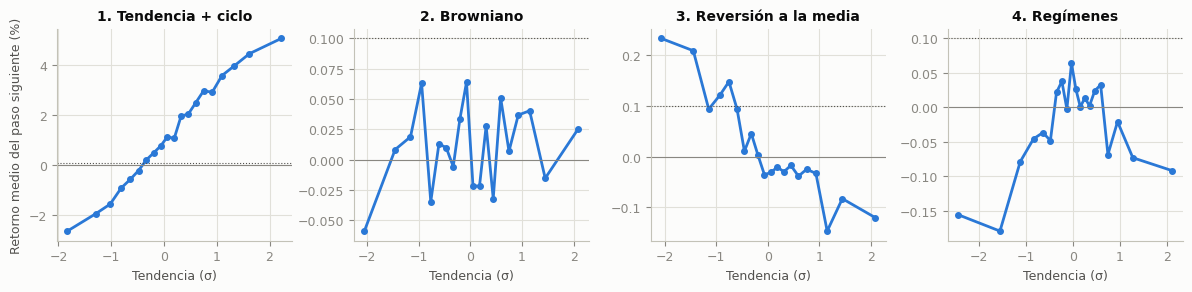

In [15]:
import matplotlib.pyplot as plt
import numpy as np

fig, ejes = plt.subplots(1, 4, figsize=(12, 3))
for ax, mercado in zip(ejes, MERCADOS):
    p = np.array(generar_series(GENERADORES[mercado], 200, 3_900_000_000))
    t = tendencias(p)[:, :-1].ravel()
    r = (p[:, 6:] / p[:, 5:-1] - 1).ravel()
    z = t / t.std()
    bordes = np.quantile(z, np.linspace(0, 1, 21))
    grupos = np.clip(np.digitize(z, bordes[1:-1]), 0, 19)
    medias = np.array([r[grupos == k].mean() for k in range(20)])
    centros = np.array([z[grupos == k].mean() for k in range(20)])
    ax.plot(centros, 100 * medias, "o-", color=graficas.COLORES["dqn"], markersize=4)
    ax.axhline(0, color=graficas.GRIS, linewidth=0.8)
    ax.axhline(0.1, color=graficas.TINTA_2, linewidth=0.8, linestyle=":")
    ax.set_title(NOMBRES_MERCADO[mercado], fontweight="bold")
    ax.set_xlabel("Tendencia (σ)")
ejes[0].set_ylabel("Retorno medio del paso siguiente (%)")
fig.tight_layout()
plt.show()

La línea de puntos marca la comisión del 0,1%. Lo que se puede esperar de un agente racional en cada mercado:

- **Ciclo:** retorno creciente con la tendencia, con mucha inercia. Se espera *momentum*.
- **Browniano:** plano. No hay señal, así que lo sensato es no operar o comprar y mantener.
- **Reversión:** retorno decreciente con la tendencia. Se espera *contrarian*, y solo en los extremos, donde supera la comisión.
- **Regímenes:** señal muy débil. Se espera poco margen sobre no operar.

## 2. Los algoritmos (ejercicio 1)

Todos los agentes guardan su red en `self.modelo` y la llaman directamente. No hay ningún `predict`: al evaluar, la red recibe **la serie entera de una vez**, sin partirla por lotes.

### Agente base

In [16]:
mostrar(Agente)
mostrar(AgenteActorCritico)

```python
class Agente:
    """Agente basado en valor: self.modelo(x) devuelve Q(s, a), y se elige la acción de mayor valor."""

    def __init__(self, modelo, normalizador):
        self.modelo = modelo
        self.normalizador = normalizador

    def preferencias(self, x):
        """Devuelve la salida de la red que ordena las acciones."""
        return self.modelo(x)

    @torch.inference_mode()
    def tablas(self, precios):
        """Evalúa la red en todos los pasos de todas las series: array (series, 2, pasos, 3)."""
        t = tendencias(precios)[:, :-1]
        salida = [self.preferencias(torch.from_numpy(self.normalizador.entrada(t, np.full_like(t, p)))).numpy()
                  for p in (0, 1)]
        return np.stack(salida, axis=1)

    def acciones_greedy(self, precios):
        """Tablas de acciones de la política greedy, listas para evaluation.simular_lote."""
        return self.tablas(precios).argmax(axis=-1)

    @torch.inference_mode()
    def __call__(self, obs):
        """Decide la acción greedy para una observación del entorno."""
        return int(self.preferencias(self.normalizador.obs(obs)).argmax())

    @torch.inference_mode()
    def mapa_politica(self, z=np.linspace(-4, 4, 81)):
        """Evalúa la política continua en una rejilla de tendencias (en desviaciones típicas).

        Devuelve las preferencias de cada acción, (2, len(z), 3). No hay intervalos: la
        frontera de decisión es una curva.
        """
        t = np.asarray(z, dtype=np.float32) * self.normalizador.escala_tendencia
        return np.stack([self.preferencias(torch.from_numpy(self.normalizador.entrada(t, np.full_like(t, p)))).numpy()
                         for p in (0, 1)])

```

```python
class AgenteActorCritico(Agente):
    """Agente basado en política: self.modelo(x) devuelve (logits del actor, valor del crítico)."""

    def preferencias(self, x):
        return self.modelo(x)[0]

    def acciones_muestreadas(self, precios, seed=0):
        """Tablas de acciones muestreadas de la política estocástica del actor."""
        logits = self.tablas(precios)
        # Muestreo de una categórica con el truco de Gumbel: argmax(logits + ruido)
        ruido = np.random.default_rng(seed).gumbel(size=logits.shape)
        return (logits + ruido).argmax(axis=-1)

```

### DQN, Doble DQN y DQN en duelo

Es el algoritmo de las transparencias 1 y 5:

1. La tabla Q se sustituye por una red con una salida lineal por acción.
2. Cada experiencia `(s, a, r, s', terminal)` se guarda en un buffer limitado.
3. Cada 4 pasos se entrena con un **minibatch al azar** del buffer, lo que rompe la correlación entre experiencias seguidas.
4. Cada 1.000 pasos se copia Q en la red objetivo Q', para que el target no se mueva con cada actualización.

La diferencia entre variantes es pequeña:

- **Doble DQN** usa Q para elegir la acción del target y Q' para valorarla, lo que reduce la sobreestimación del `max`.
- **DQN en duelo** separa la salida: $Q(s,a) = V(s) + A(s,a) - \text{media}_{a'}A(s,a')$.

In [17]:
mostrar(AgenteDQN)
mostrar(RedDuelo)

```python
class AgenteDQN(Agente):
    """El agente que aprende: la red Q en self.modelo y la red objetivo Q' en self.modelo_objetivo."""

    def __init__(self, normalizador, ocultas, alpha, gamma, doble, duelo, perdida, capacidad, max_norma_grad, rng):
        self.tipo_red = "duelo" if duelo else "q"
        super().__init__(crear_red(self.tipo_red, ocultas), normalizador)
        self.modelo_objetivo = crear_red(self.tipo_red, ocultas, clonar_estado(self.modelo))
        self.optimizador = torch.optim.Adam(self.modelo.parameters(), lr=alpha)
        self.funcion_perdida = {"mse": nn.MSELoss(), "mae": nn.L1Loss()}[perdida]
        self.buffer = Buffer(capacidad)
        self.gamma, self.doble, self.max_norma_grad, self.rng = gamma, doble, max_norma_grad, rng

    def elegir_accion(self, s, eps):
        """Elige la acción con ε-greedy."""
        if self.rng.random() < eps:
            return int(self.rng.integers(N_ACCIONES))
        with torch.inference_mode():
            return int(self.modelo(torch.from_numpy(s)).argmax())

    def aprender(self, s, a, r, s2, terminal):
        """Un paso de gradiente hacia el target de Bellman con las experiencias dadas."""
        with torch.no_grad():
            if self.doble:
                accion = self.modelo(s2).argmax(dim=1, keepdim=True)
                siguiente = self.modelo_objetivo(s2).gather(1, accion).squeeze(1)
            else:
                siguiente = self.modelo_objetivo(s2).max(dim=1).values
            objetivo = r + self.gamma * (1.0 - terminal) * siguiente
        prediccion = self.modelo(s).gather(1, a.unsqueeze(1)).squeeze(1)
        loss = self.funcion_perdida(prediccion, objetivo)
        self.optimizador.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.modelo.parameters(), self.max_norma_grad)
        self.optimizador.step()

    def sincronizar(self):
        """Copia Q en Q'."""
        self.modelo_objetivo.load_state_dict(self.modelo.state_dict())

```

```python
class RedDuelo(nn.Module):
    """DQN en duelo: Q(s,a) = V(s) + A(s,a) − media_a'(A(s,a')) (slides 5)."""

    def __init__(self, ocultas=(64, 64)):
        super().__init__()
        self.base = _mlp(2, ocultas[:-1], ocultas[-1])
        self.valor = nn.Sequential(nn.ReLU(), nn.Linear(ocultas[-1], 1))
        self.ventaja = nn.Sequential(nn.ReLU(), nn.Linear(ocultas[-1], N_ACCIONES))

    def forward(self, x):
        h = self.base(x)
        a = self.ventaja(h)
        return self.valor(h) + a - a.mean(dim=-1, keepdim=True)

```

### A3C

Varios procesos recorren series distintas a la vez, cada uno con su copia de la red. Cada `n` pasos, un trabajador calcula los retornos a `n` pasos $G_t$ y la ventaja $\delta_t = G_t - v(s_t)$, y aplica sus gradientes a los pesos globales **sin esperar a los demás**.

Esa asincronía descorrelaciona las experiencias, y por eso A3C no necesita buffer. REINFORCE es el caso límite: un solo trabajador que actualiza al final del episodio con el retorno completo, sin crítico.

In [18]:
mostrar(RedActorCritico)
mostrar(Trabajador)

```python
class RedActorCritico(nn.Module):
    """Dos modelos separados, como en las slides 7: el actor π(a|s) y el crítico v(s).

    Se separan porque el error del crítico, muy ruidoso con estos precios, tapa la
    señal de la política si comparten las capas ocultas.
    """

    def __init__(self, ocultas=(64, 64)):
        super().__init__()
        self.actor = _mlp(2, ocultas, N_ACCIONES)
        self.critico = _mlp(2, ocultas, 1)

    def forward(self, x):
        return self.actor(x), self.critico(x).squeeze(-1)

```

```python
class Trabajador:
    """Un trabajador de A3C: su red local en self.modelo y los pesos compartidos en self.modelo_global."""

    def __init__(self, indice, modelo_global, estado_adam, contador, ganancias, retornos_pct, generador, normalizador,
                 c):
        self.modelo_global, self.contador = modelo_global, contador
        self.ganancias, self.retornos_pct = ganancias, retornos_pct
        self.generador, self.normalizador, self.c = generador, normalizador, c
        torch.manual_seed(c["seed"] * 1000 + indice)
        self.rng = np.random.default_rng([c["seed"], indice])
        self.optimizador = torch.optim.Adam([{"params": modelo_global.actor.parameters(), "lr": c["alpha"]},
                                             {"params": modelo_global.critico.parameters(), "lr": c["alpha_critico"]}])
        for p, estado in zip(modelo_global.parameters(), estado_adam):
            self.optimizador.state[p] = estado
        self.modelo = crear_red(TIPO_RED, c["ocultas"])

    def _actualizar(self, estados, acciones, recompensas, obs, terminado, beta):
        """Calcula los retornos a n pasos y aplica los gradientes a los pesos globales."""
        c = self.c
        with torch.inference_mode():
            G = 0.0 if terminado else float(self.modelo.critico(self.normalizador.obs(obs)))
        retornos = np.empty(len(recompensas), dtype=np.float32)
        for k in range(len(recompensas) - 1, -1, -1):
            G = recompensas[k] + c["gamma"] * G
            retornos[k] = G

        logits, valores = self.modelo(torch.from_numpy(np.stack(estados)))
        log_probs = torch.log_softmax(logits, dim=-1)
        retornos_t = torch.from_numpy(retornos)
        ventaja = retornos_t - valores
        acciones_t = torch.as_tensor(acciones).unsqueeze(1)
        peso_actor = ventaja.detach() if c["usar_critico"] else retornos_t
        perdida_actor = -(log_probs.gather(1, acciones_t).squeeze(1) * peso_actor).mean()
        entropia = -(log_probs.exp() * log_probs).sum(dim=-1).mean()
        perdida_critico = 0.5 * ventaja.pow(2).mean() if c["perdida_critico"] == "mse" else ventaja.abs().mean()
        loss = perdida_actor - beta * entropia + perdida_critico

        self.modelo.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(self.modelo.parameters(), c["max_norma_grad"])
        # Los gradientes calculados en la red local se aplican a los pesos globales
        for p_global, p_local in zip(self.modelo_global.parameters(), self.modelo.parameters()):
            p_global.grad = p_local.grad
        self.optimizador.step()

    def _episodio(self, ep):
        c = self.c
        beta = decaimiento_exponencial(ep, c["n_episodios"], c["beta_inicial"], c["beta_final"], c["frac_decaimiento"])
        np.random.seed(semilla_entrenamiento(c["seed"], ep))
        env = SimpleTradingEnv(self.generador(n_steps=c["n_steps"]))
        obs, _ = env.reset()
        terminado = False
        ganancia = 0.0

        while not terminado:
            self.modelo.load_state_dict(self.modelo_global.state_dict())
            estados, acciones, recompensas = [], [], []
            while not terminado and len(estados) < c["n_pasos"]:
                x = self.normalizador.entrada(obs[0], obs[1])
                with torch.inference_mode():
                    probs = torch.softmax(self.modelo.actor(torch.from_numpy(x)), dim=-1).numpy()
                a = int(np.searchsorted(np.cumsum(probs), self.rng.random() * probs.sum()))
                a = min(a, len(probs) - 1)
                obs, r, terminado, _, _ = env.step(a)
                ganancia += r
                estados.append(x)
                acciones.append(a)
                recompensas.append(r / self.normalizador.escala_recompensa)
            self._actualizar(estados, acciones, recompensas, obs, terminado, beta)

        self.ganancias[ep] = ganancia
        self.retornos_pct[ep] = 100 * (env.balance / env.initial_balance - 1)

    def ejecutar(self):
        """Repite episodios hasta agotar el total. El contador compartido reparte una serie distinta a cada uno."""
        while True:
            with self.contador.get_lock():
                ep = self.contador.value
                if ep >= self.c["n_episodios"]:
                    return
                self.contador.value += 1
            self._episodio(ep)

```

### Prueba rápida: una gráfica de ganancia en directo

Antes de los experimentos largos, un entrenamiento corto de cada algoritmo en el mercado de ciclo (unos 2 minutos), para ver cómo sube la ganancia $G = \sum r$ de cada episodio mientras aprende. Es solo una demostración: los resultados serios vienen después.

DQN, 150 episodios: 30 s


A3C con 4 trabajadores, 600 episodios: 25 s


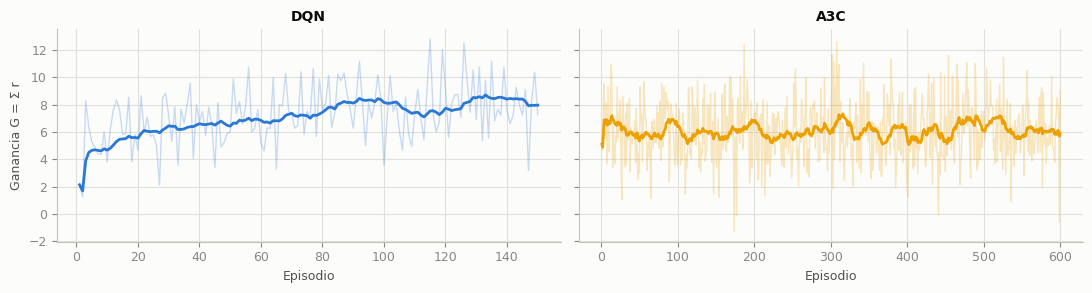

In [19]:
g = GENERADORES["ciclo"]
normalizador = Normalizador.ajustar(g)
validacion = np.array(generar_series(g, 50, SEMILLA_VALIDACION))

t0 = time.perf_counter()
demo_dqn = entrenar_dqn(g, normalizador, n_episodios=150, gamma=0.0, alpha=5e-4, seed=1, precios_validacion=validacion,
                        evaluar_cada=25)
print(f"DQN, 150 episodios: {time.perf_counter() - t0:.0f} s")
t0 = time.perf_counter()
demo_a3c = entrenar_a3c(g, normalizador, n_episodios=600, gamma=0.9, seed=1, n_trabajadores=4,
                        precios_validacion=validacion, evaluar_cada=50)
print(f"A3C con 4 trabajadores, 600 episodios: {time.perf_counter() - t0:.0f} s")

fig, ejes = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, res, nombre, color in ((ejes[0], demo_dqn, "DQN", "dqn"), (ejes[1], demo_a3c, "A3C", "a3c")):
    h = res.historial
    ax.plot(h["episodio"], h["ganancia"], color=graficas.COLORES[color], alpha=0.25, linewidth=1)
    ax.plot(h["episodio"], h["ganancia"].rolling(20, min_periods=1).mean(), color=graficas.COLORES[color])
    ax.set_title(nombre, fontweight="bold")
    ax.set_xlabel("Episodio")
ejes[0].set_ylabel("Ganancia G = Σ r")
fig.tight_layout()
plt.show()

## 3. Ajuste de hiperparámetros (ejercicio 3)

Probar todas las combinaciones sería demasiado lento, así que se ajusta por etapas. Cada una parte de lo mejor de la anterior, por mercado y solo con las series de **validación** (3 semillas × 100 series):

| Etapa | Qué ajusta | DQN | A3C |
|---|---|---|---|
| A | α × γ | α ∈ {0,0001; 0,0005; 0,002} × γ ∈ {0; 0,5; 0,9; 0,99} | α ∈ {0,0001; 0,0003; 0,001} × los mismos γ |
| B | Exploración | 3 calendarios de ε | β ∈ {0,01; 0,05; 0,2} × n ∈ {5, 20} |
| C | Pérdida | MSE o MAE (TD) | MSE o MAE (crítico) |
| D | Episodios | 400, 800, 1.600 | 800, 1.600, 3.200 |

REINFORCE hace una búsqueda más pequeña en las etapas A, B y D. Doble DQN y DQN en duelo usan la configuración de DQN, para medir solo el efecto de cada variante.

En la etapa D se elige el menor número de episodios que queda a menos de un 5% (o 1 punto) del mejor, porque entrenar más cuesta tiempo.

La siguiente celda lanza el ajuste, y su progreso va saliendo debajo. **No ejecutes el notebook dos veces a la vez:** dos procesos repetirían los mismos entrenamientos.

In [20]:
if EJECUTAR_CALCULOS:
    ajuste.main()

if hay("mejores.csv"):
    display(analisis.configuraciones_elegidas().drop(columns=["seed", "evaluar_cada"], errors="ignore").round(5))

[00:57:08] dqn/a: 0 de 144 entrenamientos


[00:57:08] dqn/b: 0 de 36 entrenamientos


[00:57:08] dqn/c: 0 de 24 entrenamientos


[00:57:08] dqn/d: 3 de 36 entrenamientos


### Etapa A: efecto de α y γ

Cada casilla es la mediana del retorno en validación, promediada entre semillas. El color es relativo dentro de cada panel.

In [ ]:
for familia, titulo in (("dqn", "DQN"), ("a3c", "A3C"), ("reinforce", "REINFORCE")):
    if hay(f"ajuste_{familia}_a.csv"):
        display(Markdown(f"**{titulo}**"))
        graficas.graficar_ajuste(familia, nombre=f"ajuste_{familia}")
        plt.show()

### Etapa C: MSE frente a MAE

La teoría da una predicción concreta. Con MSE, Q aproxima $\mathbb{E}[\text{target}]$, que es lo que pide la ecuación de Bellman. Con MAE aproxima la **mediana** del target: es más robusta al ruido de los precios, pero deja de estimar el valor esperado. Si el ruido del retorno es casi simétrico, media y mediana coinciden y ambas deberían rendir parecido. Donde hay asimetría o colas, pueden diferir.

In [ ]:
if hay("ajuste_dqn_c.csv", "ajuste_a3c_c.csv"):
    perdidas = analisis.tabla_perdidas()
    display(perdidas.round(2))
    graficas.graficar_perdidas(perdidas)
    plt.show()
elif hay("ajuste_dqn_c.csv"):
    d = pd.read_csv(RESULTADOS / "ajuste_dqn_c.csv")
    display(d.groupby(["mercado", "perdida"])[["val_mediana", "val_ganancia", "val_operaciones"]].mean().round(2))

## 4. Evaluación final (ejercicios 1 y 4)

Los agentes se entrenan de nuevo con **10 semillas nuevas** (100 a 109) y las configuraciones elegidas, y se prueban en las 100 series de test, que no se han usado para nada hasta aquí. Se evalúan también con el último control y, en los métodos de actor, con la política estocástica, como comprobación.

In [ ]:
if EJECUTAR_CALCULOS and hay("mejores.csv"):
    resultados.main()
    comparar_lotes.main()
    datos_reales.main()

### Tabla comparativa

Rendimiento en test y convergencia, por mercado y agente. El tiempo de convergencia es el episodio de convergencia por los segundos por episodio medidos con la máquina descargada, porque durante los experimentos corren muchos entrenamientos a la vez.

El **criterio de convergencia** es el primer control a partir del cual la curva de validación, suavizada, ya no se aleja de su valor final más de un 10% (o 2 puntos).

In [ ]:
if hay("test_por_serie.csv.gz", "test_baselines.csv", "entrenamientos.csv", "tiempos.csv"):
    test = analisis.cargar_test()
    tabla = analisis.tabla_resultados(test)
    tabla.to_csv(RESULTADOS / "tabla.csv", index=False)
    vista = tabla.assign(mercado=tabla.mercado.map(NOMBRES_MERCADO), agente=tabla.agente.map(NOMBRES_AGENTE))
    display(vista.set_index(["mercado", "agente"])[[
        "mediana_pct", "ganancia_G", "sharpe", "max_caida_pct", "operaciones", "dentro_pct", "supera_BH_pct",
        "mediana_min_semilla", "mediana_max_semilla", "episodios", "convergencia_ep", "convergencia_s"]].round(2))
    graficas.graficar_capital(test)
    plt.show()

### Comparación con los agentes tabulares del taller anterior

Las series de test son las mismas, así que la comparación es directa, aunque solo de medianas: Q-learning y Sarsa se entrenaron con el estado en intervalos. Responde a la pregunta de qué aporta quitar la discretización.

In [ ]:
if hay("test_por_serie.csv.gz", "test_baselines.csv", "entrenamientos.csv", "tiempos.csv"):
    ref = pd.read_csv(RESULTADOS / "referencia_tabular_fase3.csv")
    ref = ref[ref.agente.isin(["qlearning", "sarsa"])].set_index(["mercado", "agente"])["mediana_%"].unstack()
    redes = tabla[tabla.agente.isin(analisis.AGENTES_RL)].set_index(["mercado", "agente"])["mediana_pct"].unstack()
    display(ref.join(redes).loc[MERCADOS].round(1))

### ¿Son significativas las diferencias?

Cociente geométrico medio del capital final entre cada agente y cada referencia, en las mismas series, con intervalo de confianza bootstrap del 95%. Si el intervalo no incluye el 1, la diferencia es significativa.

In [ ]:
if hay("test_por_serie.csv.gz", "test_baselines.csv"):
    comparaciones = analisis.tabla_comparaciones(test)
    comparaciones.to_csv(RESULTADOS / "comparaciones.csv", index=False)
    display(comparaciones[comparaciones.referencia.isin(["buy_and_hold", "aleatorio"])].round(3))

## 5. Gráficas de ganancia por episodio

La **ganancia** es $G = \sum r$, la suma sin descontar de las recompensas de un episodio. Tiene escala comparable entre mercados, a diferencia del retorno en %.

- **La primera figura** muestra la ganancia en cada episodio de entrenamiento, mientras el agente aún explora. Por eso puede quedar por debajo de lo que el agente sabe hacer sin explorar.
- **La segunda** muestra la política sin explorar, siempre en las mismas series de validación: es la que indica si de verdad está aprendiendo.

Cada fila es un mercado, con el mismo eje y a ambos lados. Las líneas grises son buy & hold y el agente aleatorio. Cada familia tiene su propio eje x porque usa distinto número de episodios.

In [ ]:
if hay("ganancia_episodios.csv.gz", "baselines_validacion.csv"):
    graficas.graficar_ganancia_episodios()
    plt.show()

In [ ]:
if hay("curvas_validacion.csv", "baselines_validacion.csv"):
    graficas.graficar_ganancia_validacion()
    plt.show()

## 6. ¿Es la estrategia esperada? (ejercicio 2)

Como el estado es continuo, la política no es una tabla, sino una frontera de decisión. Cada panel muestra la fracción de las 10 semillas que quieren estar **dentro del mercado** según la tendencia, sin el activo (quiere comprar) y con él (no quiere vender). Si las dos filas difieren, el agente tiene histéresis: evita operar en la zona intermedia para ahorrar comisiones.

In [ ]:
if hay("mapas_politica.npz"):
    graficas.graficar_politicas()
    plt.show()

## 7. Minibatch frente a episodio entero

La base es el minibatch del buffer, como en las transparencias. Aquí se compara con que la red vea **el episodio entero de una vez** al terminar cada serie, con las mismas semillas e hiperparámetros, en dos intensidades:

- **1 pasada:** un paso de gradiente por episodio.
- **16 pasadas:** usa tantas experiencias como el minibatch (123 actualizaciones de 64 ≈ 16 pasadas de 494).

Sin buffer, la red no mezcla series distintas, y las experiencias de cada actualización están correlacionadas: es justo el problema que el buffer resuelve según las transparencias. Esta comparación no elige nada: la configuración final no cambia.

In [ ]:
if hay("lotes_test.csv.gz", "test_por_serie.csv.gz"):
    lotes = pd.read_csv(RESULTADOS / "lotes_test.csv.gz")
    base = test[test.agente == "dqn"].assign(variante="Minibatch")
    lotes = lotes.assign(variante=lotes.pasadas.map({1: "Episodio, 1 pasada", 16: "Episodio, 16 pasadas"}))
    comparacion = pd.concat([base, lotes]).groupby(["mercado", "variante"]).agg(
        mediana_pct=("retorno_pct", "median"), ganancia_G=("ganancia", "mean"), operaciones=("operaciones", "mean"))
    display(comparacion.loc[MERCADOS].round(2))

## 8. Prueba con datos reales: índices y fondos

Prueba secundaria, como en el taller anterior, con dos índices y dos fondos descargados de Yahoo Finance:

| Activo | Tipo |
|---|---|
| S&P 500 | Índice, sin dividendos |
| IBEX 35 | Índice, sin dividendos |
| Vanguard Wellington | Fondo mixto, con dividendos |
| Vanguard Total Bond | Fondo de bonos, con dividendos |

De cada activo solo hay una historia, así que el protocolo cambia. Se entrena con **tramos de 500 días al azar hasta 2015**, para que cada episodio vea una serie distinta. Se eligen los pesos con **2016-2018** y se evalúa de una sola pasada desde **2019**. Los tramos solo reparten los episodios: el estado que ve la red sigue siendo continuo.

No se ajusta nada con datos reales, porque con una sola historia se sobreajustaría: se usa la configuración del mercado de regímenes.

Hay que leerlo con cautela: **cada activo tiene una única historia de test**, y 2019-2026 fue muy alcista para la renta variable. Además, los fondos de inversión suelen limitar las operaciones frecuentes, así que una estrategia muy activa no sería realista en ellos.

In [ ]:
if hay("reales_resultados.csv"):
    reales = pd.read_csv(RESULTADOS / "reales_resultados.csv")
    resumen = reales.groupby(["activo", "agente", "periodo"])["retorno_pct"].median().unstack("periodo")
    display(resumen[["entrenamiento", "validacion", "test"]].round(1))